In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path("../src").resolve()))
%load_ext autoreload
%autoreload 2
from uplift.metrics import qini_auc, qini_curve, bootstrap_qini, calibration_table

DATA = Path("../data/processed")
FIG = Path("../reports/figures")

# Nur das Testset wird gebraucht: Outcome, Treatment und die gespeicherten Vorhersagen aus Notebook 03
df = pd.read_parquet(DATA / "criteo_uplift_v2.1.parquet", columns=["treatment", "visit"])
split = pd.read_parquet(DATA / "split.parquet")["split"].to_numpy()
te = df[split == 2]
del df
preds = pd.read_parquet(DATA / "preds_test.parquet")
assert preds.index.equals(te.index)   # gleiche Zeilen in gleicher Reihenfolge
y_te, w_te = te["visit"].to_numpy(), te["treatment"].to_numpy()

MODELS = list(preds.columns)
UPLIFT_MODELS = [m for m in MODELS if m not in ("random", "response")]
print(MODELS)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
['random', 'response', 's_learner', 't_learner', 'x_learner', 'dr_learner', 'causal_forest']


In [3]:
# Punktschätzer zur Kontrolle – müssen mit reports/model_comparison.csv übereinstimmen
point = pd.Series({m: qini_auc(y_te, w_te, preds[m]) for m in MODELS}, name="qini_auc")
point.round(4)

random          -0.0044
response         0.3413
s_learner        0.3595
t_learner        0.3280
x_learner        0.3594
dr_learner       0.3600
causal_forest    0.3559
Name: qini_auc, dtype: float64

In [4]:
# 200 Bootstrap-Runden des Testsets (Poisson-Gewichte, gepaart über alle Modelle), dauert ca. 4–5 Minuten
# Erfasst nur die Unsicherheit durch das Testset, nicht die durch das Training
boot, boot_curves = bootstrap_qini(y_te, w_te, {m: preds[m].to_numpy() for m in MODELS}, n_boot=200, seed=0)

ci = pd.DataFrame({"qini_auc": point,
                   "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975),
                   "sd": boot.std()})
ci.round(4)

,qini_auc,ci_low,ci_high,sd
random,-0.0044,-0.0210,0.0140,0.0088
response,0.3413,0.3317,0.3524,0.0053
s_learner,0.3595,0.3411,0.3758,0.0086
t_learner,0.3280,0.3077,0.3488,0.0109
x_learner,0.3594,0.3421,0.3797,0.0095
dr_learner,0.3600,0.3436,0.3794,0.0096
causal_forest,0.3559,0.3452,0.3693,0.0063


In [5]:
# Gepaarte Differenzen: in jeder Runde bekommen alle Modelle dieselbe Stichprobe.
# Gemeinsame Schwankungen (z. B. "zufällig viele Visits in der Treatment-Gruppe") heben sich auf,
# daher ist das Intervall der Differenz viel enger, als die Einzelintervalle vermuten lassen
def paired_diff(ref):
    d = boot.sub(boot[ref], axis=0).drop(columns=ref)
    return pd.DataFrame({"diff": point.drop(ref) - point[ref],
                         "ci_low": d.quantile(0.025), "ci_high": d.quantile(0.975),
                         "p_besser": (d > 0).mean()})   # Anteil der Runden, in denen das Modell vorne liegt

print("Gegenüber dem Response-Modell:")
display(paired_diff("response").round(4))
print("Gegenüber dem S-Learner:")
display(paired_diff("s_learner").round(4))

Gegenüber dem Response-Modell:


,diff,ci_low,ci_high,p_besser
random,-0.3457,-0.3641,-0.3248,0.000
s_learner,0.0181,0.0032,0.0330,0.995
t_learner,-0.0133,-0.0367,0.0082,0.105
x_learner,0.0181,0.0017,0.0364,0.985
dr_learner,0.0187,0.0003,0.0360,0.980
causal_forest,0.0146,0.0047,0.0272,0.995


Gegenüber dem S-Learner:


,diff,ci_low,ci_high,p_besser
random,-0.3639,-0.3844,-0.3375,0.000
response,-0.0181,-0.0330,-0.0032,0.005
t_learner,-0.0314,-0.0504,-0.0116,0.000
x_learner,-0.0000,-0.0154,0.0133,0.570
dr_learner,0.0006,-0.0153,0.0177,0.570
causal_forest,-0.0035,-0.0185,0.0095,0.425


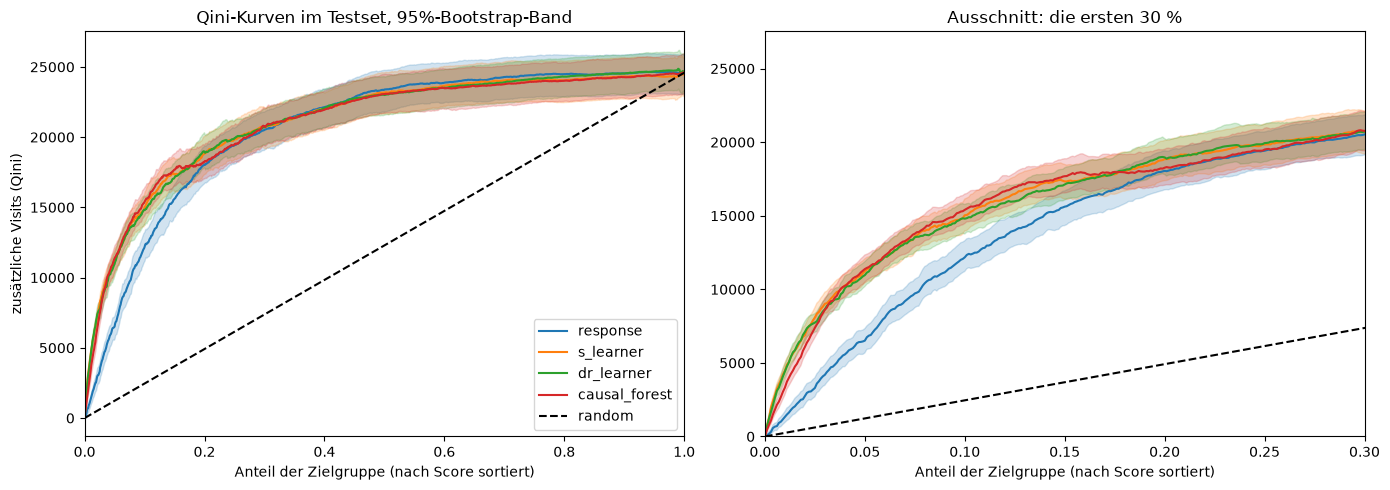

In [6]:
# Qini-Kurven mit punktweisem 95%-Band (Perzentile über die Bootstrap-Runden)
grid = np.linspace(0, 1, 1001)   # Raster, auf dem bootstrap_qini die Kurven ablegt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, xmax in zip(axes, (1.0, 0.3)):   # rechts: Ausschnitt der ersten 30 %
    for m in ["response", "s_learner", "dr_learner", "causal_forest"]:
        frac, q = qini_curve(y_te, w_te, preds[m])
        line, = ax.plot(frac, q, label=m)
        lo, hi = np.percentile(boot_curves[m], [2.5, 97.5], axis=0)
        ax.fill_between(grid, lo, hi, color=line.get_color(), alpha=0.2)
    ax.plot([0, 1], [0, q[-1]], "k--", label="random")
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Anteil der Zielgruppe (nach Score sortiert)")
axes[1].set_ylim(0, None)
axes[0].set_ylabel("zusätzliche Visits (Qini)")
axes[0].set_title("Qini-Kurven im Testset, 95%-Bootstrap-Band")
axes[1].set_title("Ausschnitt: die ersten 30 %")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "qini_bootstrap.png", dpi=120)

In [7]:
# Kalibrierung: 10 gleich große Gruppen nach vorhergesagtem Uplift (0 = höchster)
# Vergleich mittlere Vorhersage vs. beobachteter Uplift (Rate_T − Rate_C) in derselben Gruppe
# Das Response-Modell fehlt: es sagt P(visit) vorher, keinen Uplift
calib = {m: calibration_table(y_te, w_te, preds[m]) for m in UPLIFT_MODELS}
pd.concat({m: t[["predicted", "observed"]] for m, t in calib.items()}, axis=1).round(4)

s_learner          t_learner          x_learner          dr_learner  \
      predicted observed predicted observed predicted observed  predicted   
group                                                                       
0        0.0611   0.0621    0.0667   0.0583    0.0567   0.0615     0.0485   
1        0.0083   0.0072    0.0093   0.0063    0.0069   0.0075     0.0069   
2        0.0024   0.0014    0.0023   0.0022    0.0028   0.0023     0.0030   
3        0.0010   0.0008    0.0009   0.0008    0.0017   0.0005     0.0023   
4        0.0005   0.0008    0.0005   0.0008    0.0011   0.0013     0.0017   
5        0.0003   0.0004    0.0003   0.0005    0.0009   0.0009     0.0017   
6        0.0002   0.0007    0.0001   0.0003    0.0008   0.0000     0.0017   
7        0.0001  -0.0002    0.0000   0.0005    0.0008   0.0006     0.0017   
8        0.0001   0.0006   -0.0001   0.0004    0.0008   0.0003     0.0017   
9       -0.0005   0.0010   -0.0059   0.0061    0.0000   0.0009     0.0013   

               causal_forest           
      observed     predicted observed  
group                                  
0       0.0611        0.0463   0.0636  
1       0.0109        0.0094   0.0073  
2       0.0013        0.0047   0.0065  
3       0.0017        0.0022   0.0010  
4       0.0014        0.0012   0.0010  
5       0.0008        0.0008   0.0002  
6       0.0005        0.0006   0.0001  
7       0.0004        0.0004   0.0003  
8       0.0003        0.0002   0.0006  
9       0.0003       -0.0003   0.0007

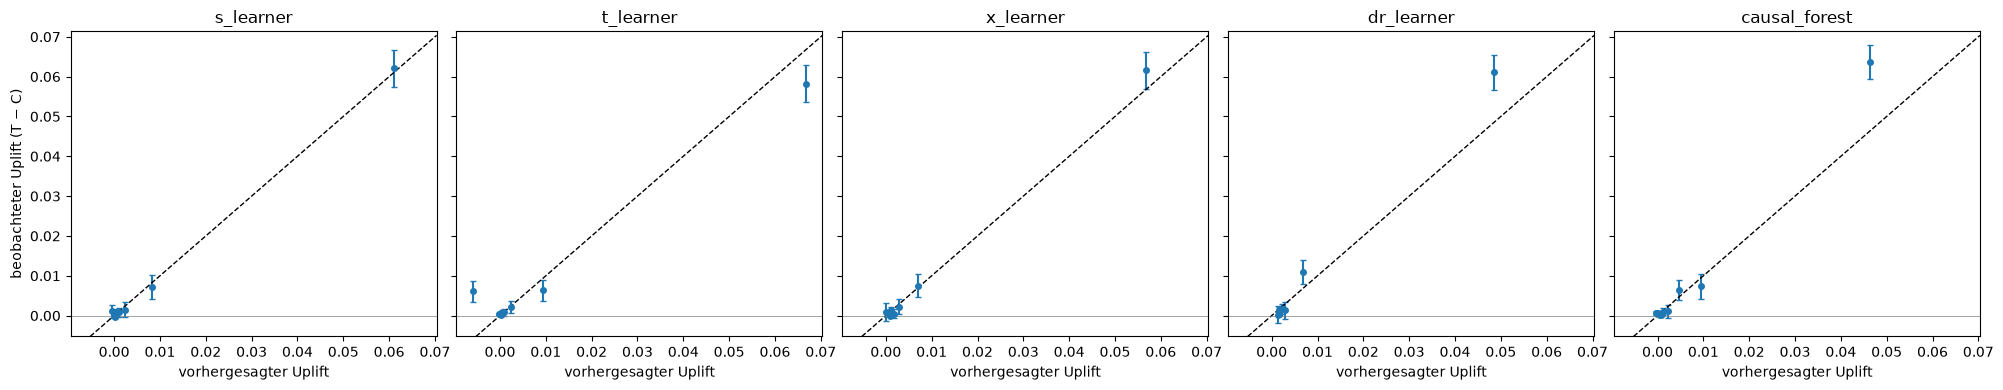

In [8]:
# Kalibrierungsdiagramm: Punkte auf der Diagonale = Vorhersage stimmt im Mittel; Fehlerbalken = 95%-KI
fig, axes = plt.subplots(1, len(calib), figsize=(4 * len(calib), 4), sharex=True, sharey=True)
for ax, (m, t) in zip(axes, calib.items()):
    ax.errorbar(t["predicted"], t["observed"], yerr=1.96 * t["se"], fmt="o", ms=4, capsize=2)
    ax.axline((0, 0), slope=1, color="k", ls="--", lw=1)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(m)
    ax.set_xlabel("vorhergesagter Uplift")
axes[0].set_ylabel("beobachteter Uplift (T − C)")
fig.tight_layout()
fig.savefig(FIG / "calibration.png", dpi=120)

In [9]:
# Kalibrierung im Mittel: alle Modelle sagen im Schnitt ~0,007 vorher, die Differenz der Mittelwerte ist ~0,010.
# Gegenprobe: dieselbe Differenz innerhalb von 100 gleich großen Gruppen nach Response-Score (≈ Grundrate) bilden und mitteln
ate_naive = y_te[w_te == 1].mean() - y_te[w_te == 0].mean()
strata = calibration_table(y_te, w_te, preds["response"], n_bins=100)
ate_strat = strata["observed"].mean()   # gleich große Gruppen → einfacher Mittelwert
print(f"Differenz der Mittelwerte (gesamt):     {ate_naive:.4f}")
print(f"Differenz innerhalb der Gruppen:        {ate_strat:.4f}")
print("mittlerer vorhergesagter Uplift:", preds[UPLIFT_MODELS].mean().round(4).to_dict())

# Ursache: Anteil der Behandelten je Response-Dezil (bei echter Randomisierung überall ≈ 0,85 ± 0,0013)
dec = calibration_table(y_te, w_te, preds["response"])
dec[["share_treated"]].T.round(4)

Differenz der Mittelwerte (gesamt):     0.0103
Differenz innerhalb der Gruppen:        0.0066
mittlerer vorhergesagter Uplift: {'s_learner': 0.0074, 't_learner': 0.0074, 'x_learner': 0.0073, 'dr_learner': 0.007, 'causal_forest': 0.0065}


group,0,1,2,3,4,5,6,7,8,9
share_treated,0.8615,0.8525,0.8493,0.847,0.8454,0.8478,0.8481,0.8482,0.85,0.8502


In [10]:
ci.to_csv("../reports/qini_bootstrap.csv")
pd.concat(calib, names=["model", "group"]).to_csv("../reports/calibration.csv")